# 02. EDA Brut

Exploration rapide du dataset fusionné pour valider le déséquilibre de classes, la structure et les distributions principales.


In [1]:
# Importation des bibliothèques principales
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *
from pyspark.sql.functions import col, round as spark_round

from pyspark.ml.stat import *
from pyspark.ml import Pipeline
from pyspark.ml.functions import vector_to_array
from pyspark.ml.feature import  VectorAssembler , RobustScaler
from pyspark.ml.feature import StringIndexer, OneHotEncoder, StandardScaler
from pyspark.ml.classification import RandomForestClassifier,LogisticRegression,GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator ,MulticlassClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

#  Visualisation et analyse complémentaire

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from builtins import round


In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
ARTIFACTS_ROOT = PROJECT_DIR / "artifacts"
MODELS_ROOT = PROJECT_DIR / "models"
INPUT_STAGE_DIR = ARTIFACTS_ROOT / "01_setup_load_merge" / "data"

for _dir in (ARTIFACTS_ROOT, MODELS_ROOT, INPUT_STAGE_DIR):
    _dir.mkdir(parents=True, exist_ok=True)

In [ ]:
# Création de la session Spark

spark = SparkSession.builder \
    .appName("DetectionFraude") \
    .master("local[8]") \
    .config("spark.driver.memory", "10g") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate() 
spark 

In [4]:
# fonciton nettoyage de mémoire 
def cleanup(*vars_to_del):
    for var in vars_to_del:
        del var
    import gc; gc.collect()
    spark.catalog.clearCache()

In [5]:
df = spark.read.parquet((INPUT_STAGE_DIR / "01_train_merged.parquet").as_posix())

## 2. Exploration rapide des données (EDA brute)

### Objectif de cette section : Analyse exploratoire rapide (inspection générale)

Cette étape vise à obtenir une première vue d'ensemble du dataset fusionné, afin de :

1. Examiner la variable cible `isFraud` et valider l’hypothèse d’un fort déséquilibre
2. Confirmer la structure générale après fusion (types, format)
3. Étudier la structure identitaire via la variable `has_identity`
4. Explorer quelques statistiques descriptives clés pour orienter l’analyse

 Cette phase permet de valider les hypothèses initiales et de préparer les prochaines étapes : détection d’anomalies, EDA approfondie, puis modélisation.

### 2.1. Analyse de la variable cible `isFraud`

In [6]:
total = df.count()

# Distribution avec pourcentage
df.groupBy("isFraud") \
  .count() \
  .withColumn("perc_%", spark_round(col("count") / total * 100, 2)) \
  .orderBy("isFraud") \
  .show()
  

+-------+------+------+
|isFraud| count|perc_%|
+-------+------+------+
|      0|569877|  96.5|
|      1| 20663|   3.5|
+-------+------+------+



###  Visualisation de la variable cible isFraud

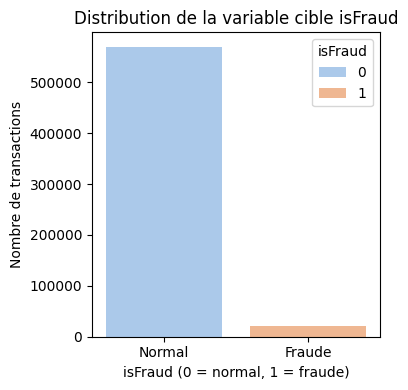

In [7]:
# 2. Visualisation de la variable cible
fraude_simple = df.groupBy("isFraud").count().toPandas()
fraude_simple.columns = ["isFraud", "count"]

plt.figure(figsize=(4, 4))
sns.barplot(data=fraude_simple, x="isFraud" ,  y="count",hue="isFraud", palette="pastel")

plt.title("Distribution de la variable cible isFraud")
plt.xlabel("isFraud (0 = normal, 1 = fraude)")
plt.ylabel("Nombre de transactions")
plt.xticks([0, 1], ["Normal", "Fraude"])
plt.tight_layout()
plt.show()

# Libere la mémoire de la variable df
cleanup(fraude_simple)

###  Interprétation

L’analyse de la variable cible `isFraud` confirme un **fort déséquilibre de classes** :

- **96,5 %** des transactions sont **non frauduleuses**
- Seulement **3,5 %** sont **frauduleuses**

 Cette distribution est typique des **problèmes de détection de fraude**, où le signal (fraude) est **rare** comparé au bruit (transactions normales).

 Ce déséquilibre aura un **impact direct sur la modélisation** :
- Il rend l'exactitude peu fiables
- Il nécessitera l’utilisation de **métriques adaptées** (ex. : précision ,F1-score, AUC-ROC, PR Curve)
- Il faudra peut-être recourir à des techniques comme le **rebalancing** (undersampling, oversampling, SMOTE, etc.)

Cette étape valide donc l'une des **hypothèses critiques** posées en amont du projet.

### 2.2 Structure du dataset fusionné


In [8]:
# Affichage du schéma (types des col)
df.printSchema()

root
 |-- TransactionID: integer (nullable = true)
 |-- isFraud: integer (nullable = true)
 |-- TransactionDT: integer (nullable = true)
 |-- TransactionAmt: double (nullable = true)
 |-- ProductCD: string (nullable = true)
 |-- card1: integer (nullable = true)
 |-- card2: double (nullable = true)
 |-- card3: double (nullable = true)
 |-- card4: string (nullable = true)
 |-- card5: double (nullable = true)
 |-- card6: string (nullable = true)
 |-- addr1: double (nullable = true)
 |-- addr2: double (nullable = true)
 |-- dist1: double (nullable = true)
 |-- dist2: double (nullable = true)
 |-- P_emaildomain: string (nullable = true)
 |-- R_emaildomain: string (nullable = true)
 |-- C1: double (nullable = true)
 |-- C2: double (nullable = true)
 |-- C3: double (nullable = true)
 |-- C4: double (nullable = true)
 |-- C5: double (nullable = true)
 |-- C6: double (nullable = true)
 |-- C7: double (nullable = true)
 |-- C8: double (nullable = true)
 |-- C9: double (nullable = true)
 |-- C10:

In [9]:
df.select("TransactionID", "DeviceType", "id_01", "id_30", "isFraud" ).show(5)

+-------------+----------+-----+-----+-------+
|TransactionID|DeviceType|id_01|id_30|isFraud|
+-------------+----------+-----+-----+-------+
|      2987022|      NULL|-15.0| NULL|      0|
|      2987034|      NULL| NULL| NULL|      0|
|      2987039|      NULL| NULL| NULL|      0|
|      2987040|   desktop|-10.0| NULL|      0|
|      2987058|      NULL| NULL| NULL|      0|
+-------------+----------+-----+-----+-------+
only showing top 5 rows



###  Interprétation

L’ensemble des colonnes est bien interprété par Spark :
- Types numériques (`double`), chaînes (`string`) et entiers (`integer`) correctement détectés
- Toutes les colonnes sont `nullable`, laissant entrevoir une forte proportion de valeurs manquantes
- Les colonnes issues d’`identity.csv` (`DeviceType`, `id_01`, etc.) apparaissent en `NULL` pour de nombreuses transactions

Cette observation valide le comportement de la jointure `LEFT` : toutes les transactions sont présentes, mais seules certaines sont enrichies par des données d’identité.

 Nous allons créer une variable binaire `has_identity` afin de capturer cette distinction et d’analyser son lien potentiel avec la fraude.


### 2.3 Étude de la variable `has_identity`

Cette variable binaire a été créée pour indiquer si une transaction dispose ou non d'informations identitaires issues du fichier `identity.csv` :

- 1 si au moins une information d’identité (ex. : `DeviceType`, `id_01`, `id_30`) est présente,
- 0 si **toutes ces colonnes d'identité sont vides** cela signifie que la transaction **n'était pas présente** dans le fichier d'identité ( NULL )

In [ ]:
df = df.withColumn(
    "has_identity",
    when(
        col("DeviceType").isNotNull() |
        col("id_01").isNotNull() |
        col("id_30").isNotNull() |
        col("id_31").isNotNull() |
        col("DeviceInfo").isNotNull(),
        1
    ).otherwise(0))

# compte des fraudes/non-fraudes par has_identity
fraude_par_identity = ( df.groupBy("has_identity", "isFraud")
      .count()
      .orderBy("has_identity", "isFraud"))

# total des transactions par groupe de has_identity
total_par_groupe = ( df.groupBy("has_identity")
      .count()
      .withColumnRenamed("count", "total"))

# join + ajout du taux de fraude dans chaque groupe
fraude_par_identity = (
    fraude_par_identity
    .join(total_par_groupe, on="has_identity", how="left")
    .withColumn("fraude_%", spark_round((col("count") / col("total")) * 100, 2))
    .orderBy("has_identity", "isFraud"))

fraude_par_identity.show()

+------------+-------+------+------+--------+
|has_identity|isFraud| count| total|fraude_%|
+------------+-------+------+------+--------+
|           0|      0|436962|446307|   97.91|
|           0|      1|  9345|446307|    2.09|
|           1|      0|132915|144233|   92.15|
|           1|      1| 11318|144233|    7.85|
+------------+-------+------+------+--------+



In [11]:
df.select(mean("has_identity")).show()

+------------------+
| avg(has_identity)|
+------------------+
|0.2442391709283029|
+------------------+



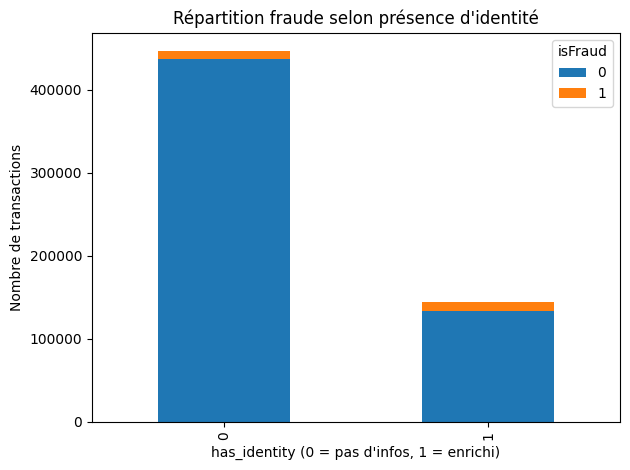

In [ ]:
fraude_pd = fraude_par_identity.toPandas()

# graphique
pivot = fraude_pd.pivot(index="has_identity", columns="isFraud", values="count")
pivot.plot(kind="bar", stacked=True)
plt.title("Répartition fraude selon présence d'identité")
plt.xlabel("has_identity (0 = pas d'infos, 1 = enrichi)")
plt.ylabel("Nombre de transactions")
plt.legend(title="isFraud")
plt.tight_layout()
plt.show()

# libere la mémoire de la var df
cleanup(fraude_pd)

###  Interprétation

- Environ **76 %** des transactions ne possèdent **aucune information d’identité** (`has_identity = 0`)
- Les **taux de fraude sont très différents selon les groupes** :
    - **2,09 %** de fraude dans les transactions anonymes
    - **7,85 %** de fraude dans les transactions enrichies

Cela peut sembler contre-intuitif : on aurait pu s’attendre à ce que les fraudeurs évitent de fournir leur identité.  
Mais ces résultats suggèrent que :
- Les fraudeurs peuvent aussi fournir des identités **falsifiées** ou **volées**
- L'anonymat **n’est pas nécessairement un indicateur de fraude**, mais reste une information pertinente

La variable `has_identity` sera conservée comme **feature structurelle importante** pour la modélisation. Son importance réelle sera étudiée via des outils d’interprétabilité (ex. : SHAP).


### 2.4. Statistiques descriptives clés


####  Statistiques de base : TransactionAmt (montant)

In [13]:
#statistiques descriptives ciblées

cols = ["TransactionID","TransactionAmt", "isFraud", "TransactionDT",
        "ProductCD", "card4","card6"]

df.select(cols).describe().show()

+-------+------------------+------------------+-------------------+-----------------+---------+----------------+---------------+
|summary|     TransactionID|    TransactionAmt|            isFraud|    TransactionDT|ProductCD|           card4|          card6|
+-------+------------------+------------------+-------------------+-----------------+---------+----------------+---------------+
|  count|            590540|            590540|             590540|           590540|   590540|          588963|         588969|
|   mean|         3282269.5|135.02717637247326|0.03499000914417313|7372311.310116165|     NULL|            NULL|           NULL|
| stddev|170474.35832112623| 239.1625220137341| 0.1837546341784141|4617223.646539682|     NULL|            NULL|           NULL|
|    min|           2987000|             0.251|                  0|            86400|        C|american express|    charge card|
|    max|           3577539|         31937.391|                  1|         15811131|        W|  

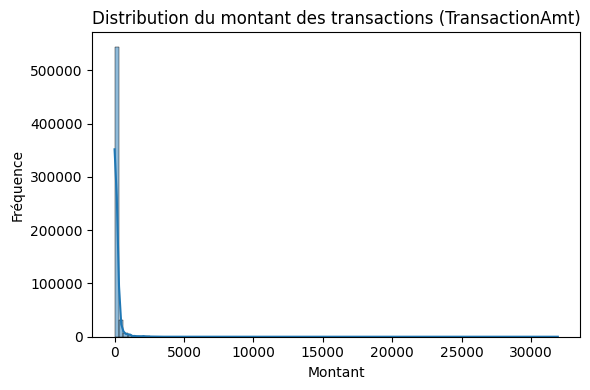

In [14]:
df_pd = df.select("TransactionAmt").toPandas()

plt.figure(figsize=(6, 4))
sns.histplot(df_pd["TransactionAmt"], bins=100, kde=True)
plt.title("Distribution du montant des transactions (TransactionAmt)")
plt.xlabel("Montant")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()

# libere la mémoire de la variable df
cleanup(df_pd)

### Interprétation de `TransactionAmt`

La variable `TransactionAmt` présente une distribution fortement asymétrique à droite :

- le montant minimal est de **0,251** ;
- le montant moyen est de **135,03** ;
- le montant maximal atteint **31 937,391** ;
- la majorité des observations se concentre sur des montants relativement faibles, tandis qu’une longue traîne contient quelques montants très élevés.

Ces valeurs élevées peuvent correspondre à des observations extrêmes, mais leur statut d’outlier devra être confirmé à l’aide de statistiques robustes, notamment les quantiles et l’écart interquartile.

####  Variables catégorielles : `ProductCD`, `card4`, `card6`

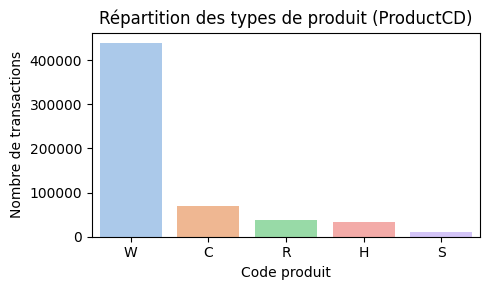

In [15]:
product_dist = df.groupBy("ProductCD").count().toPandas().sort_values(by="count", ascending=False)

plt.figure(figsize=(5, 3))
sns.barplot(data=product_dist, x="ProductCD",hue="ProductCD", y="count", palette="pastel")
plt.title("Répartition des types de produit (ProductCD)")
plt.xlabel("Code produit")
plt.ylabel("Nombre de transactions")
plt.tight_layout()
plt.show()

# libere la mémoire de la variable df
cleanup(product_dist)

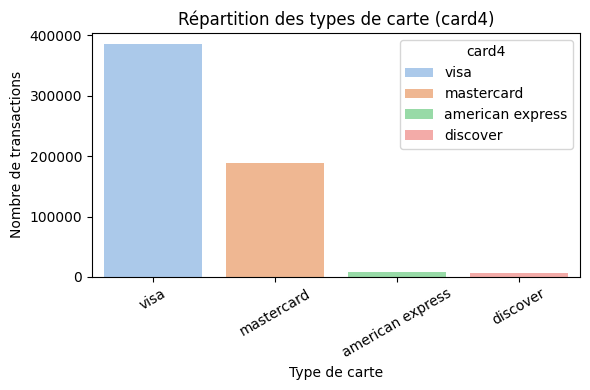

In [16]:

# GroupBy + count pour card4
card4_count = df.groupBy("card4").count().orderBy("count", ascending=False)

card4_pd = card4_count.toPandas()

plt.figure(figsize=(6, 4))
sns.barplot(data=card4_pd, x="card4", y="count",hue="card4", palette="pastel")
plt.title("Répartition des types de carte (card4)")
plt.xlabel("Type de carte")
plt.ylabel("Nombre de transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

cleanup(card4_count, card4_pd)

In [17]:
df.groupBy("card6").count().orderBy("count", ascending=False).show()

+---------------+------+
|          card6| count|
+---------------+------+
|          debit|439938|
|         credit|148986|
|           NULL|  1571|
|debit or credit|    30|
|    charge card|    15|
+---------------+------+



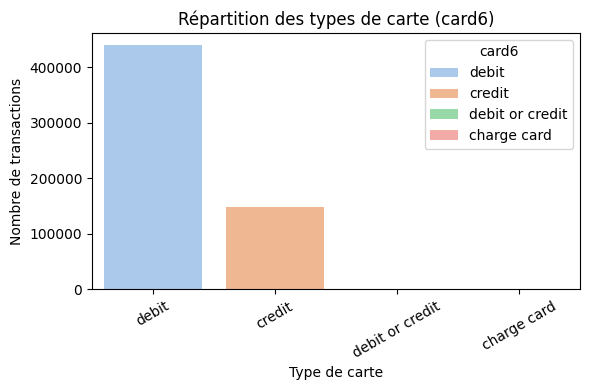

In [18]:
# GroupBy + count pour card6
card6_count = df.groupBy("card6").count().orderBy("count", ascending=False)

# Conversion en Pandas
card6_pd = card6_count.toPandas()

plt.figure(figsize=(6, 4))
sns.barplot(data=card6_pd, x="card6", y="count",hue="card6", palette="pastel")
plt.title("Répartition des types de carte (card6)")
plt.xlabel("Type de carte")
plt.ylabel("Nombre de transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

cleanup(card6_count, card6_pd)

### Interprétation des variables catégorielles

Les distributions des principales variables catégorielles sont déséquilibrées :

- `ProductCD` est dominée par la modalité `W`, qui représente plus de 70 % des transactions ;
- `card4` est principalement composée des modalités `Visa` et `Mastercard` ;
- `card6` est dominée par les cartes de débit avec **439 938 transactions**, soit environ **74,50 %**, devant les cartes de crédit avec **148 986 transactions**, soit environ **25,23 %**.

Les modalités rares et les valeurs manquantes devront être traitées de manière cohérente entre les jeux d’entraînement et de validation. Un regroupement des modalités rares pourra être envisagé uniquement s’il améliore la robustesse du modèle.

###  Conclusion de l’analyse exploratoire rapide (EDA brute)

Cette phase d’exploration préliminaire a permis de :

1. **Valider la structure générale du dataset**, suite à la fusion des fichiers `transaction` et `identity`
2. Confirmer un **fort déséquilibre de la variable cible `isFraud`** ( 3,5 % de fraudes)
3. Identifier une variable clé `has_identity`, qui distingue les transactions “enrichies” (24 %) des “anonymes” (76 %), et révèle un **taux de fraude 4x plus élevé chez les enrichies**
4. Visualiser les distributions des principales variables numériques (`TransactionAmt`) et catégorielles (`ProductCD`, `card4`, `card6`), toutes fortement asymétriques avec quelques modalités dominantes

 Ces analyses constituent une **base solide pour orienter les étapes suivantes** :
- Le **nettoyage ciblé** des données (valeurs manquantes, modalités rares)
- Une **EDA approfondie post-nettoyage** avec des croisements, corrélations, et outliers
- Un **feature engineering guidé par les insights observés ici**

 Nous passons maintenant à la phase **d’inspection et détection des anomalies**, pour préparer le dataset à la modélisation.